In [1]:
from pathlib import Path

import harmonypy as hm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.colors import LinearSegmentedColormap

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

adata = sc.read_h5ad(DIR_PROCESADOS / "03_anotado.h5ad")
tcel = adata[adata.obs["tipo"] == "Linfocito T"].copy()
tcel.obs["muestra"] = tcel.obs["muestra"].cat.remove_unused_categories()

print(tcel)
print(tcel.obs["muestra"].value_counts().sort_values())

AnnData object with n_obs × n_vars = 1581 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden', 'es_T', 'tipo'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'condicion_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'muestra_colors', 'neighbors', 'pca', 'rank_genes_groups', 'scrublet', 'tipo_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'


In [2]:
import math

import seaborn as sns

COLORES = {"Sano": "#7a7a7a", "NL": "#5b8db8", "LS": "#c0504d"}
ORDEN = ["Sano", "NL", "LS"]
CMAP_EXPR = LinearSegmentedColormap.from_list("expresion", ["#e6e6e6", "#c0504d", "#5c1f1d"])


def colores_categoria(adata, columna, paleta):
    """Guarda en adata.uns los colores de una columna categórica, en el orden de sus categorías."""
    cats = adata.obs[columna].cat.categories
    if isinstance(paleta, dict):
        adata.uns[f"{columna}_colors"] = [paleta[c] for c in cats]
    else:
        adata.uns[f"{columna}_colors"] = [mcolors.to_hex(c) for c in paleta[:len(cats)]]


def umap_condicion(ax, adata, size):
    """UMAP coloreado por condición, en orden aleatorio para que ninguna condición tape a otra."""
    xy = adata.obsm["X_umap"]
    cond = adata.obs["condicion"].astype(str).to_numpy()
    orden_aleatorio = np.random.default_rng(0).permutation(len(cond))
    ax.scatter(xy[orden_aleatorio, 0], xy[orden_aleatorio, 1], s=size, linewidths=0,
               c=[COLORES[c] for c in cond[orden_aleatorio]], rasterized=True)
    for c in ORDEN:
        ax.scatter([], [], s=40, color=COLORES[c], label=c)
    ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
    ax.set_title("Condición")
    ax.set_axis_off()

COLORES_SUBTIPO = {
    "CD4 memoria": "#7fa3c4",
    "CD4 con estrés": "#b9c7d6",
    "CD8 GZMK+": "#c0504d",
    "CD8 IFNG+": "#e3a07f",
    "CD8 / gamma delta": "#a67c9e",
    "Treg": "#6f9a6a",
}


def boxplot_condicion(ax, datos, y, titulo="", ylabel="", negrita=False, sin_punto=()):
    """Caja sólida por condición con un punto negro por muestra.

    sin_punto: muestras que cuentan para la caja pero cuyo punto se dibuja aparte.
    """
    sns.boxplot(data=datos, x="condicion", y=y, order=ORDEN,
                hue="condicion", hue_order=ORDEN, palette=COLORES, width=0.6,
                showfliers=False, dodge=False, linecolor="black", linewidth=1,
                medianprops={"color": "black", "linewidth": 2}, legend=False, ax=ax)
    puntos = datos[~datos["muestra"].isin(sin_punto)] if sin_punto else datos
    sns.stripplot(data=puntos, x="condicion", y=y, order=ORDEN,
                  color="black", size=4, jitter=0.05, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_title(titulo, fontsize=10, fontweight="bold" if negrita else "normal")


def rejilla_condicion(largo, panel, y, titulos, ylabel, ncols=3, resaltar=()):
    """Un boxplot por panel. titulos: {panel: texto del título}."""
    nfilas = math.ceil(len(titulos) / ncols)
    fig, axes = plt.subplots(nfilas, ncols, figsize=(3 * ncols, 3 * nfilas), squeeze=False)
    for ax, (nombre, titulo) in zip(axes.flat, titulos.items()):
        boxplot_condicion(ax, largo[largo[panel] == nombre], y, titulo,
                          negrita=nombre in resaltar)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    for ax in axes.flat[len(titulos):]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig

In [3]:
sc.pp.highly_variable_genes(tcel, n_top_genes=2000, batch_key="muestra")

excluir = tcel.var_names.str.match(r"^(TR[ABDG][VJ]|IG[HKL][VJ]|MT-|RP[SL])")
tcel.var.loc[excluir, "highly_variable"] = False
print("Genes excluidos:", excluir.sum(), "| Genes variables:", tcel.var["highly_variable"].sum())

Genes excluidos: 184 | Genes variables: 1922


In [4]:
sc.pp.pca(tcel, n_comps=30, mask_var="highly_variable")

ho = hm.run_harmony(tcel.obsm["X_pca"], tcel.obs, "muestra", random_state=0)
z = np.asarray(ho.Z_corr)
assert z.shape == tcel.obsm["X_pca"].shape, z.shape
tcel.obsm["X_pca_harmony"] = z

2026-11-02 12:36:34,110 - harmonypy - INFO - Running Harmony


2026-11-02 12:36:34,111 - harmonypy - INFO -   Parameters:


2026-11-02 12:36:34,111 - harmonypy - INFO -     max_iter_harmony: 10


2026-11-02 12:36:34,112 - harmonypy - INFO -     max_iter_kmeans: 4


2026-11-02 12:36:34,112 - harmonypy - INFO -     epsilon_cluster: 0.001


2026-11-02 12:36:34,113 - harmonypy - INFO -     epsilon_harmony: 0.01


... (13 outputs left out)

2026-11-02 12:36:34,171 - harmonypy - INFO - Iteration 3 of 10


2026-11-02 12:36:34,184 - harmonypy - INFO - Iteration 4 of 10


2026-11-02 12:36:34,196 - harmonypy - INFO - Iteration 5 of 10


2026-11-02 12:36:34,209 - harmonypy - INFO - Converged after 5 iterations


In [5]:
sc.pp.neighbors(tcel, use_rep="X_pca_harmony", n_pcs=20)
sc.tl.umap(tcel, random_state=0)
sc.tl.leiden(tcel, resolution=0.5, flavor="igraph", n_iterations=2,
             key_added="leiden_T", random_state=0)
tcel.obs["leiden_T"].value_counts().sort_index()

leiden_T
0     423
1      59
2     132
3     256
4     156
5      92
6      52
7      63
8     271
9      48
10     29
Name: count, dtype: int64

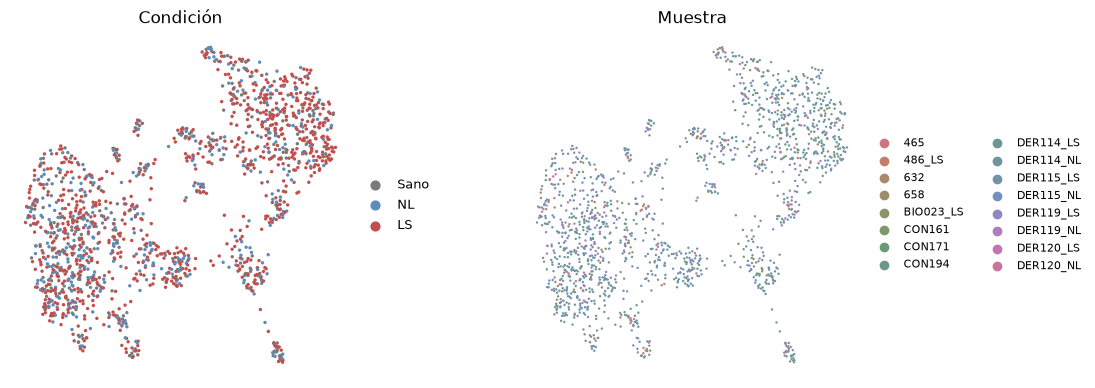

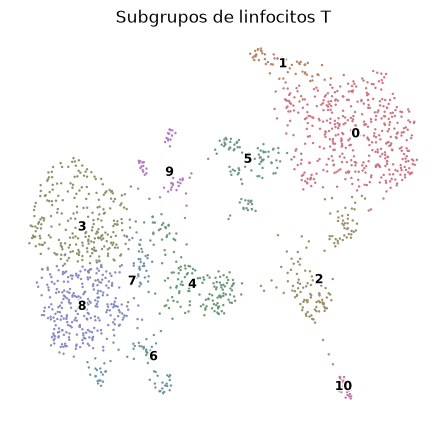

In [6]:
colores_categoria(tcel, "condicion", COLORES)
colores_categoria(tcel, "muestra", sns.husl_palette(tcel.obs["muestra"].nunique(), s=0.45, l=0.6))
colores_categoria(tcel, "leiden_T", sns.husl_palette(tcel.obs["leiden_T"].nunique(), s=0.45, l=0.6))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
umap_condicion(axes[0], tcel, size=6)
sc.pl.umap(tcel, color="muestra", ax=axes[1], frameon=False, size=12,
           title="Muestra", legend_fontsize=8, show=False)
fig.subplots_adjust(wspace=0.5)
fig.savefig(DIR_FIGURAS / "umap_T_muestra_condicion.png", dpi=300, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(5.5, 5))
sc.pl.umap(tcel, color="leiden_T", ax=ax, frameon=False, size=12, title="Subgrupos de linfocitos T",
           legend_loc="on data", legend_fontsize=9, legend_fontoutline=2, show=False)
fig.savefig(DIR_FIGURAS / "umap_T_subclusters.png", dpi=300, bbox_inches="tight")

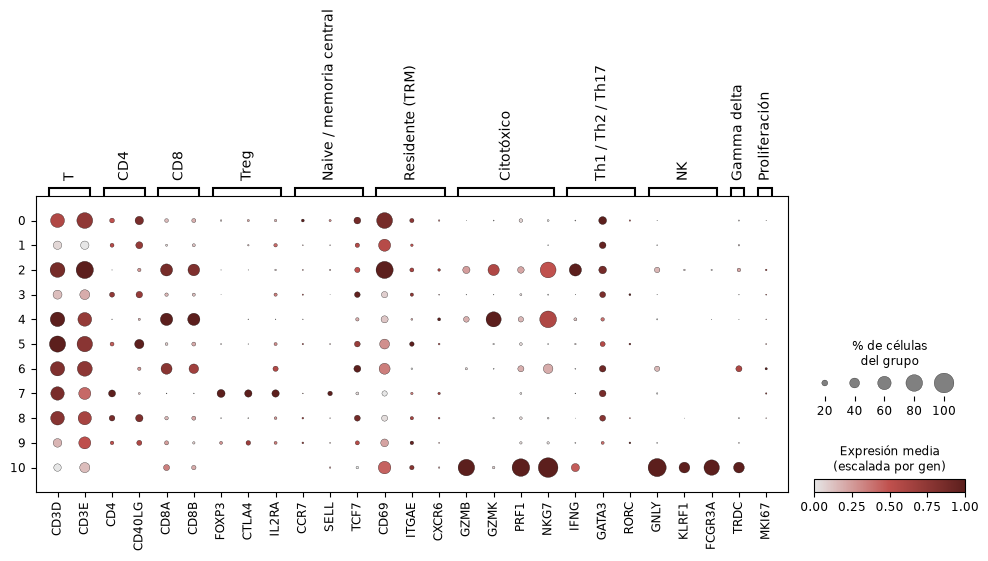

In [7]:
marcadores_T = {
    "T": ["CD3D", "CD3E"],
    "CD4": ["CD4", "CD40LG"],
    "CD8": ["CD8A", "CD8B"],
    "Treg": ["FOXP3", "CTLA4", "IL2RA"],
    "Naive / memoria central": ["CCR7", "SELL", "TCF7"],
    "Residente (TRM)": ["CD69", "ITGAE", "CXCR6"],
    "Citotóxico": ["GZMB", "GZMK", "PRF1", "NKG7"],
    "Th1 / Th2 / Th17": ["IFNG", "GATA3", "RORC"],
    "NK": ["GNLY", "KLRF1", "FCGR3A"],
    "Gamma delta": ["TRDC"],
    "Proliferación": ["MKI67"],
}
marcadores_T = {k: [g for g in v if g in tcel.var_names] for k, v in marcadores_T.items()}

sc.pl.dotplot(tcel, marcadores_T, groupby="leiden_T", standard_scale="var", cmap=CMAP_EXPR, size_title="% de células\ndel grupo", colorbar_title="Expresión media\n(escalada por gen)",  show=False)
plt.savefig(DIR_FIGURAS / "dotplot_T_subclusters.png", dpi=300, bbox_inches="tight")


In [8]:
por_muestra = pd.crosstab(tcel.obs["leiden_T"], tcel.obs["muestra"])
por_muestra["total"] = por_muestra.sum(axis=1)
por_muestra["muestras_con_5_o_mas"] = (por_muestra.drop(columns="total") >= 5).sum(axis=1)
por_muestra

muestra,465,486_LS,632,658,BIO023_LS,CON161,CON171,CON194,DER114_LS,DER114_NL,DER115_LS,DER115_NL,DER119_LS,DER119_NL,DER120_LS,DER120_NL,total,muestras_con_5_o_mas
leiden_T,,,,,,,,,,,,,,,,,,
0,5,2,13,0,6,9,27,7,150,13,109,39,26,6,2,9,423,13
1,1,0,3,0,1,3,7,3,12,3,8,7,6,2,0,3,59,5
2,3,0,1,0,3,6,4,0,27,11,42,22,6,2,2,3,132,6
3,5,8,8,2,4,1,15,9,35,20,74,31,16,18,2,8,256,12
4,1,9,1,0,1,2,4,0,16,8,68,37,4,3,0,2,156,5
5,5,2,1,0,2,2,6,2,17,7,25,15,3,3,0,2,92,6
6,2,3,2,0,2,2,1,0,5,9,13,2,4,5,0,2,52,4
7,2,6,5,0,1,2,2,2,10,5,15,7,3,3,0,0,63,6
8,6,5,2,1,4,3,12,12,38,28,86,47,11,12,0,4,271,10


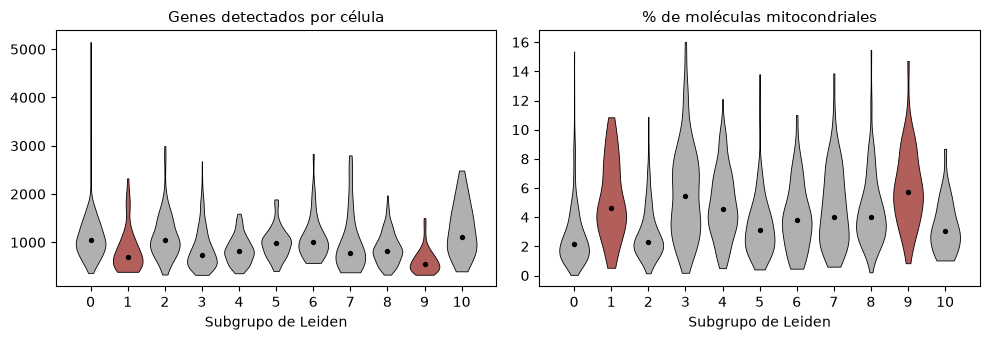

In [9]:
colores_calidad = {c: "#c0504d" if c in ("1", "9") else "#b0b0b0"
                   for c in tcel.obs["leiden_T"].cat.categories}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (metrica, titulo) in zip(axes, {"n_genes_by_counts": "Genes detectados por célula",
                                        "pct_counts_mt": "% de moléculas mitocondriales"}.items()):
    sns.violinplot(data=tcel.obs, x="leiden_T", y=metrica, hue="leiden_T", palette=colores_calidad,
                   cut=0, inner=None, linewidth=0.6, linecolor="black", density_norm="width",
                   dodge=False, legend=False, ax=ax)
    medianas = tcel.obs.groupby("leiden_T", observed=True)[metrica].median()
    ax.scatter(range(len(medianas)), medianas, color="black", s=8, zorder=3)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("Subgrupo de Leiden")
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "violin_T_calidad_subclusters.png", dpi=300, bbox_inches="tight")

In [10]:
anot_T = {
    "0": "CD4 con estrés",
    "1": "Baja calidad",
    "2": "CD8 IFNG+",
    "3": "CD4 memoria",
    "4": "CD8 GZMK+",
    "5": "CD4 con estrés",
    "6": "CD8 / gamma delta",
    "7": "Treg",
    "8": "CD4 memoria",
    "9": "Baja calidad",
    "10": "NK",
}
assert set(anot_T) == set(tcel.obs["leiden_T"].cat.categories)
tcel.obs["subtipo_T"] = tcel.obs["leiden_T"].map(anot_T).astype("category")

tcel_limpio = tcel[~tcel.obs["subtipo_T"].isin(["NK", "Baja calidad"])].copy()
tcel_limpio.obs["subtipo_T"] = tcel_limpio.obs["subtipo_T"].cat.remove_unused_categories()
tcel_limpio.obs["subtipo_T"].value_counts()

subtipo_T
CD4 memoria          527
CD4 con estrés       515
CD8 GZMK+            156
CD8 IFNG+            132
Treg                  63
CD8 / gamma delta     52
Name: count, dtype: int64

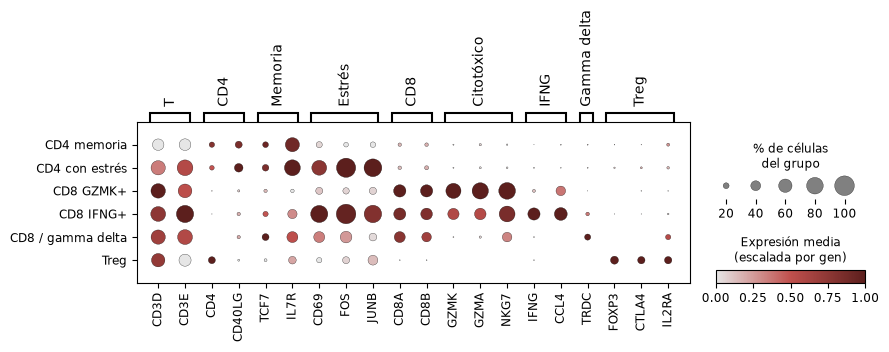

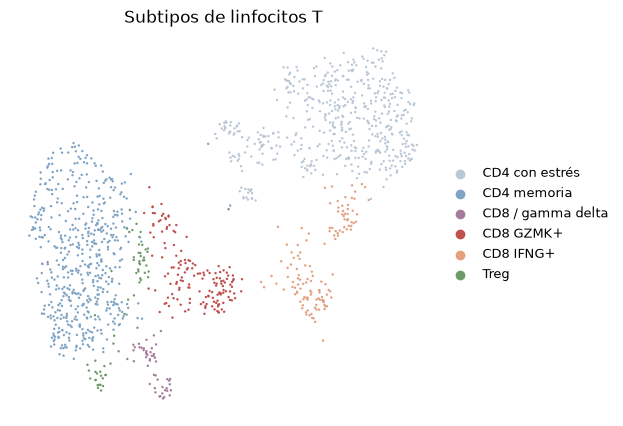

In [11]:
marcadores_subtipos = {
    "T": ["CD3D", "CD3E"],
    "CD4": ["CD4", "CD40LG"],
    "Memoria": ["TCF7", "IL7R"],
    "Estrés": ["CD69", "FOS", "JUNB"],
    "CD8": ["CD8A", "CD8B"],
    "Citotóxico": ["GZMK", "GZMA", "NKG7"],
    "IFNG": ["IFNG", "CCL4"],
    "Gamma delta": ["TRDC"],
    "Treg": ["FOXP3", "CTLA4", "IL2RA"],
}
orden_subtipos = ["CD4 memoria", "CD4 con estrés", "CD8 GZMK+", "CD8 IFNG+", "CD8 / gamma delta", "Treg"]

sc.pl.dotplot(tcel_limpio, marcadores_subtipos, groupby="subtipo_T", categories_order=orden_subtipos,
              standard_scale="var", cmap=CMAP_EXPR, size_title="% de células\ndel grupo", colorbar_title="Expresión media\n(escalada por gen)", show=False)
plt.savefig(DIR_FIGURAS / "dotplot_T_subtipos.png", dpi=300, bbox_inches="tight")

colores_categoria(tcel_limpio, "subtipo_T", COLORES_SUBTIPO)
fig, ax = plt.subplots(figsize=(5.5, 5))
sc.pl.umap(tcel_limpio, color="subtipo_T", ax=ax, frameon=False, size=12,
           title="Subtipos de linfocitos T", legend_fontsize=9, show=False)
fig.savefig(DIR_FIGURAS / "umap_T_subtipos.png", dpi=300, bbox_inches="tight")

In [12]:
sc.tl.rank_genes_groups(tcel_limpio, groupby="subtipo_T", method="wilcoxon",
                        key_added="rank_subtipos")

tecnicos = r"^(MT-|MTRNR2L|RP[SL]|TR[ABDG][VJ]|IG[HKL][VJ])"
filas = []
for s in tcel_limpio.obs["subtipo_T"].cat.categories:
    df = sc.get.rank_genes_groups_df(tcel_limpio, group=s, key="rank_subtipos")
    df = df[~df["names"].str.match(tecnicos) & (df["logfoldchanges"] > 0)].head(15)
    df.insert(0, "subtipo", s)
    filas.append(df)
    print(f"{s}: {', '.join(df['names'])}")

top_subtipos = pd.concat(filas)
top_subtipos.round(3).to_csv(DIR_TABLAS / "marcadores_subtipos_T.csv", index=False)

CD4 con estrés: FOS, DUSP1, JUND, JUNB, HSPA8, EIF1, DNAJB1, FOSB, H3F3B, RGCC, FTH1, HSPA1B, PPP1R15A, DNAJA1, HSP90AA1
CD4 memoria: MALAT1, ARHGAP15, AHNAK, LPAR6, IKZF1, SON, NKTR, TXNIP, N4BP2L2, DDX17, IL7R, SYNE2, TNRC6B, PCNX1, RORA
CD8 / gamma delta: ZNF683, FXYD2, CTSW, KLRK1, HOPX, IFITM1, HCST, S100A6, CRIP1, CCL5, TIMP1, LGALS1, SEPTIN11, IFITM2, MATK
CD8 GZMK+: CCL5, NKG7, CD74, GZMA, GZMK, HLA-DRB1, CST7, GZMH, CD8A, HCST, HLA-DPB1, HLA-DRA, CD8B, GIMAP7, CTSW
CD8 IFNG+: CCL5, NKG7, CCL4, CST7, ZFP36, FOS, CTSW, IFNG, CD69, DUSP1, JUND, DUSP2, SRGN, NR4A2, HLA-DRB1
Treg: LINC02694, IKZF2, GBP5, TTN, FOXN3, TIGIT, MAN1A2, TBC1D4, FOXP3, SKAP1, ICOS, IL32, PHTF2, CTLA4, CASK


In [13]:
prop = pd.crosstab(tcel_limpio.obs["muestra"], tcel_limpio.obs["subtipo_T"],
                   normalize="index").mul(100)
prop.columns = prop.columns.astype(str)
prop["condicion"] = tcel_limpio.obs.groupby("muestra", observed=True)["condicion"].first()
prop["n_T"] = tcel_limpio.obs["muestra"].value_counts()
prop = prop[prop["n_T"] >= 20]
prop.round(1).to_csv(DIR_TABLAS / "subtipos_T_por_muestra.csv")
prop.round(1)

subtipo_T,CD4 con estrés,CD4 memoria,CD8 / gamma delta,CD8 GZMK+,CD8 IFNG+,Treg,condicion,n_T
muestra,,,,,,,,
465,34.5,37.9,6.9,3.4,10.3,6.9,Sano,29
486_LS,11.4,37.1,8.6,25.7,0.0,17.1,LS,35
632,42.4,30.3,6.1,3.0,3.0,15.2,Sano,33
BIO023_LS,34.8,34.8,8.7,4.3,13.0,4.3,LS,23
CON161,40.7,14.8,7.4,7.4,22.2,7.4,Sano,27
CON171,46.5,38.0,1.4,5.6,5.6,2.8,Sano,71
CON194,28.1,65.6,0.0,0.0,0.0,6.2,Sano,32
DER114_LS,56.0,24.5,1.7,5.4,9.1,3.4,LS,298
DER114_NL,19.8,47.5,8.9,7.9,10.9,5.0,NL,101


In [14]:
from scipy.stats import false_discovery_control, mannwhitneyu, spearmanr

subtipos = [c for c in prop.columns if c not in ("condicion", "n_T")]
orden = {"Sano": 0, "NL": 1, "LS": 2}

filas = []
for s in subtipos:
    g = {c: prop.loc[prop["condicion"] == c, s] for c in orden}
    rho = spearmanr(prop["condicion"].map(orden), prop[s])
    filas.append({"subtipo": s,
                  "mediana_Sano": g["Sano"].median(),
                  "mediana_NL": g["NL"].median(),
                  "mediana_LS": g["LS"].median(),
                  "p_NL_vs_Sano": mannwhitneyu(g["NL"], g["Sano"]).pvalue,
                  "p_LS_vs_Sano": mannwhitneyu(g["LS"], g["Sano"]).pvalue,
                  "rho_tendencia": rho.statistic,
                  "p_tendencia": rho.pvalue})

res = pd.DataFrame(filas).set_index("subtipo")
for col in ["p_NL_vs_Sano", "p_LS_vs_Sano", "p_tendencia"]:
    res[col.replace("p_", "q_")] = false_discovery_control(res[col])

res.round(3).to_csv(DIR_TABLAS / "subtipos_T_estadistica.csv")
res.round(3)

,mediana_Sano,mediana_NL,mediana_LS,p_NL_vs_Sano,p_LS_vs_Sano,rho_tendencia,p_tendencia,q_NL_vs_Sano,q_LS_vs_Sano,q_tendencia
subtipo,,,,,,,,,,
CD4 con estrés,40.741,23.401,34.783,0.063,0.690,-0.189,0.518,0.190,0.829,0.680
CD4 memoria,37.931,43.762,36.986,0.190,0.548,-0.231,0.428,0.286,0.821,0.680
CD8 / gamma delta,6.061,7.789,5.479,0.413,0.548,0.168,0.567,0.495,0.821,0.680
CD8 GZMK+,3.448,7.294,5.479,0.063,0.222,0.377,0.183,0.190,0.821,0.680
CD8 IFNG+,5.634,10.446,9.060,0.556,0.917,0.042,0.887,0.556,0.917,0.887
Treg,6.897,4.225,4.110,0.111,0.548,-0.294,0.308,0.222,0.821,0.680


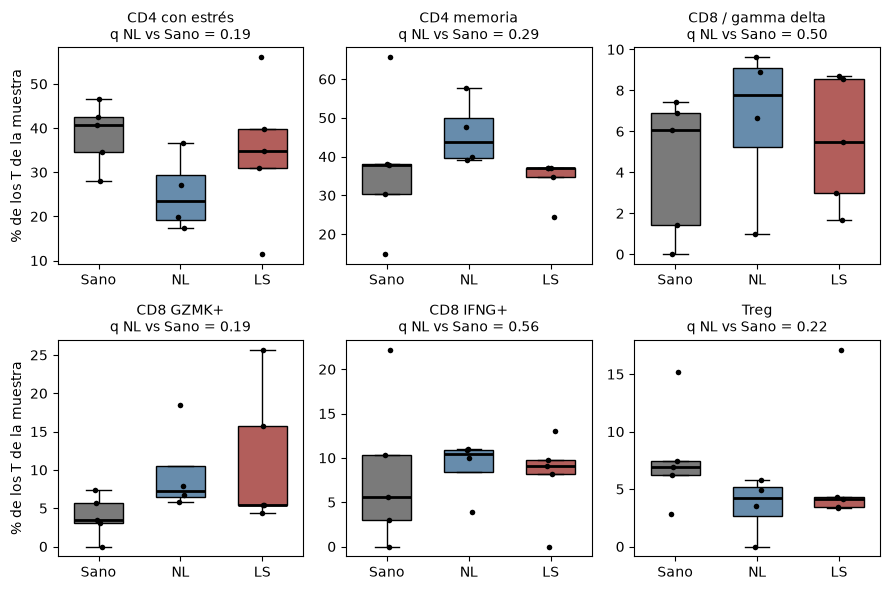

In [15]:
largo = prop.reset_index().melt(id_vars=["muestra", "condicion", "n_T"],
                                var_name="subtipo", value_name="pct")
titulos = {s: f"{s}\nq NL vs Sano = {res.loc[s, 'q_NL_vs_Sano']:.2f}" for s in subtipos}

fig = rejilla_condicion(largo, "subtipo", "pct", titulos, "% de los T de la muestra")
fig.savefig(DIR_FIGURAS / "subtipos_T_por_condicion.png", dpi=300, bbox_inches="tight")

In [16]:
tcel_limpio.write_h5ad(DIR_PROCESADOS / "04_linfocitos_T.h5ad")